### Predicting House Prices with Linear Regression
##### Objective: Build and evaluate a linear regression model that predicts house prices based on features such as area, location, number of rooms, and age. Develop end-to-end skills from data cleaning through to model interpretation.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
predict = pd.read_csv("House Price Prediction Dataset.csv")

In [3]:
# Check for the data info
predict.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


In [4]:
# Check the stats of the data
predict.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [5]:
predict.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


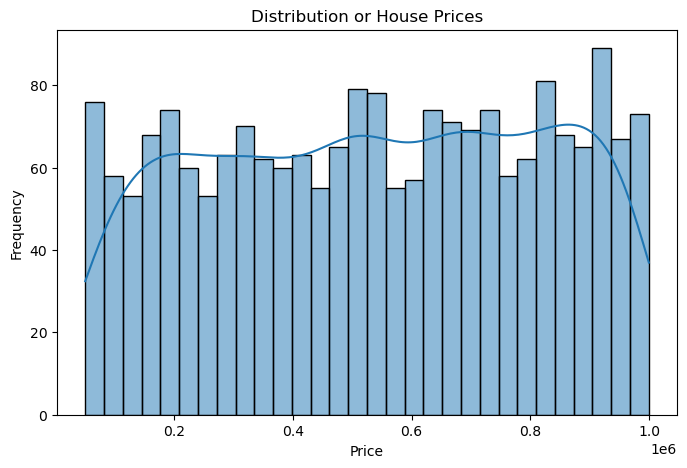

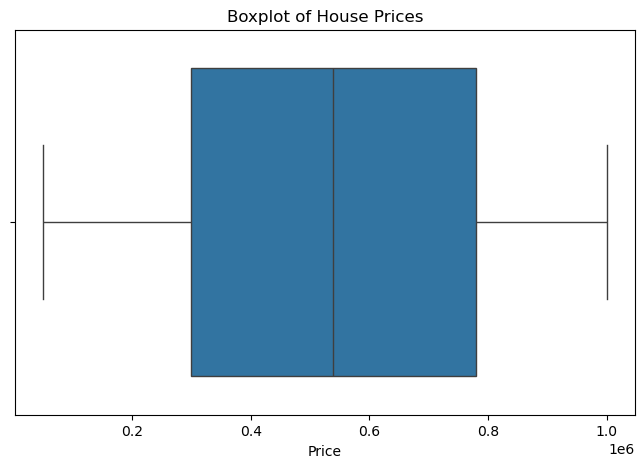


Skewness: -0.06435063707629374


In [6]:
# Distribution of Price - visualization
## Histogram + KDE
plt.figure(figsize=(8, 5))
sns.histplot(predict['Price'], kde=True, bins=30)
plt.title('Distribution or House Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

## Boxplot to spot outlier/skew
plt.figure(figsize=(8, 5))
sns.boxplot(x=predict['Price'])
plt.title('Boxplot of House Prices')
plt.show()

## Skewness value
print('\nSkewness:', predict['Price'].skew())


Price shws minimal skew (-0.06), and the boxplot confirms no significant outliers. The distribution is close to uniform across the price range, so no transformation of the target variable is needed before modeling.

I hypothesize Location is a strong predictor of price, since houses in different areas typically face different demand and cost of living. I'll verify this by comparing average price across location groups, and later via One-Hot Encoding + correlation heatmap. I also expect Area, Bedrooms, Bathrooms, and Condition to contribute, though a quick look at the first few rows suggests price may depend on a combination of these features rather any single.

In [7]:
predict.groupby('Location')['Price'].mean().sort_values(ascending=False)

Location
Suburban    557416.333333
Rural       538613.943038
Downtown    536059.661290
Urban       518963.548454
Name: Price, dtype: float64

Update after testing: The group-by results shows only a ~7% spread in average price across locations (`Suburban: $557k`, `Rural: $539k`, `Downtown: $536k`, `Urban: $519k`), which is smaller than expected. This suggests Location may be a weaker predictor than initially hypothesized. I'll confirm this with the correlation heatmap and focus more attention on Area and other numeric features.

In [8]:
# Check for missing values
predict.isna().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

The dataset contains no missing values across any column, so no imputation or row/column removal was necessary before processing to encoding.

In [9]:
# One-Hot Encode categorical columns
predict_encoded = pd.get_dummies(predict, columns=['Location', 'Condition', 'Garage'], drop_first=True)
predict_encoded.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1,1360,5,4,3,1970,149919,False,False,False,False,False,False,False
1,2,4272,5,4,3,1958,424998,False,False,False,False,False,False,False
2,3,3592,2,2,3,1938,266746,False,False,False,False,True,False,False
3,4,966,4,2,2,1902,244020,False,True,False,True,False,False,True
4,5,4926,1,4,2,1975,636056,False,False,False,True,False,False,True


I used drop_first=True in One-Hot Encoding to aviod multicollinearity. Downtown (Location), similarity for Condition/Garage, serve as baseline categories, represented implicity when all their respective dummy columns are False

In [10]:
# ID isn't a predictive feature, but an identifier - drop it
predict_encoded = predict_encoded.drop('Id', axis=1)

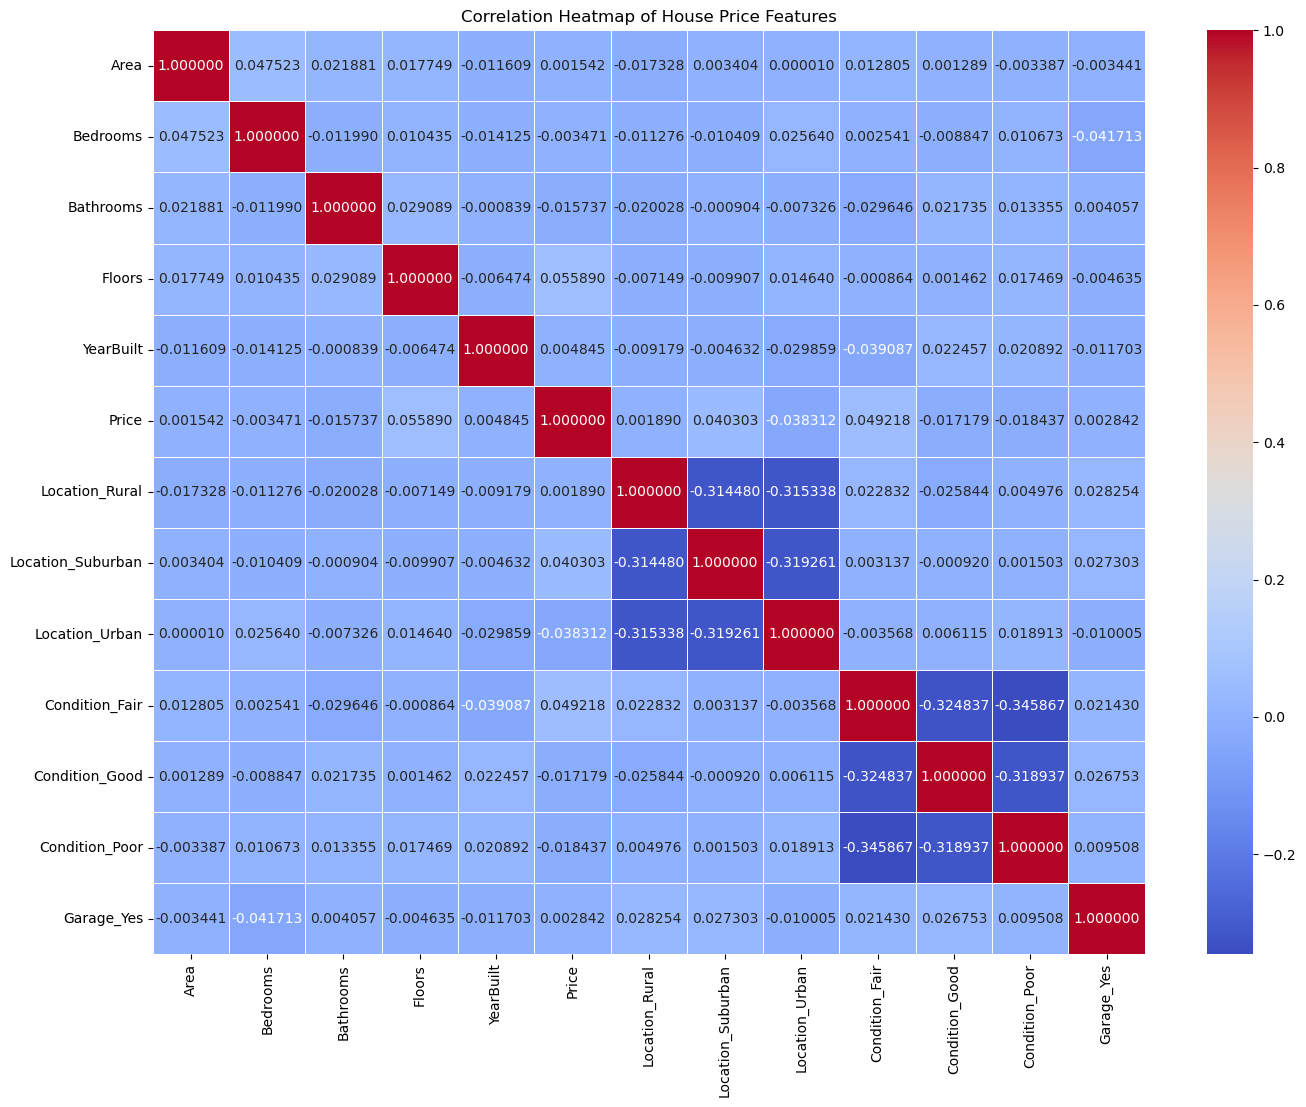

In [11]:
# Identify features most correlated with house price
plt.figure(figsize=(16, 12))
correlation_matrix = predict_encoded.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='2f', linewidths=0.5)
plt.title('Correlation Heatmap of House Price Features')
plt.show()

In [12]:
# Clean list of features correlated with house price
predict_encoded.corr()['Price'].sort_values(ascending=False)

Price                1.000000
Floors               0.055890
Condition_Fair       0.049218
Location_Suburban    0.040303
YearBuilt            0.004845
Garage_Yes           0.002842
Location_Rural       0.001890
Area                 0.001542
Bedrooms            -0.003471
Bathrooms           -0.015737
Condition_Good      -0.017179
Condition_Poor      -0.018437
Location_Urban      -0.038312
Name: Price, dtype: float64

Correlation Analysis: None of the features show a meaniful correlation with Price, Floor is the highest at only 0.056, and all others are below 0.05 in magnitude. This suggeats Price in this dataset does not have a strong relationship with any single feature, including Area, Location, or Bedrooms, contrary to typical real-world housing data. This may indicate the data was synthetically/randomly generated. I'll proceed with the linear regression model as required by the task, but expect a low R² score given this lack correlation.

In [13]:
# Split rows (80/20) into two separate groups for model testing
from sklearn.model_selection import train_test_split

X = predict_encoded.drop('Price', axis=1)
Y = predict_encoded['Price']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (1600, 12)
Testing set shape: (400, 12)


In [14]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, Y_train)

print('Model trained successfully')

Model trained successfully


In [15]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Generate predictions on the test set
Y_pred = model.predict(X_test)

# Calculate metrics
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

print('Mean Squared Error (MSE):', mse)
print('Root Mean Squared Error (RMSE):', rmse)
print('R² Score:', r2)

Mean Squared Error (MSE): 78321466146.0328
Root Mean Squared Error (RMSE): 279859.72583784326
R² Score: -0.006717808430749761


Model Evaluation: The Linear Regression model achieved an RMSE of `~$279,860` and an R² score of -0.0067. A near-zero (or slightly neagtive) R² indicates the model explains essentially none of the variance in house prices, performing no better than simply predicting the mean price for every house. This is consistent with the correlation analysis, which showed no feature correlated with Price above 0.06 in magnitude. This strongly suggests the dataset's Price values were generated independently of the other feature (e.g., randomly), rather than as a true function of Area, Location, Bedrooms, etc.

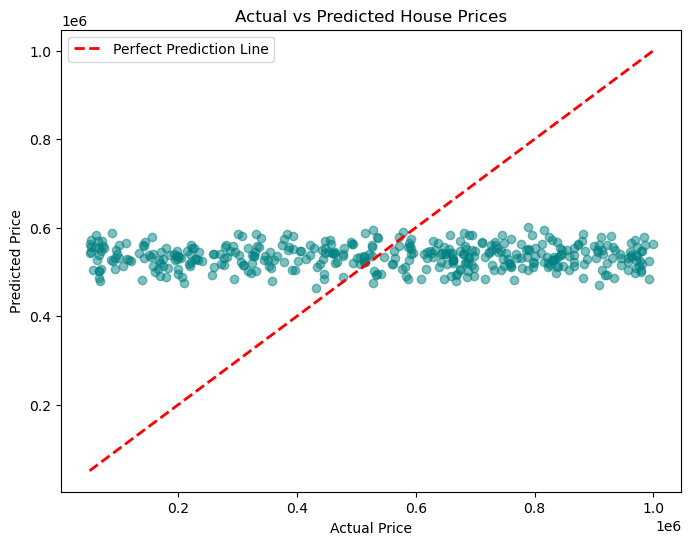

In [16]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, Y_pred, alpha=0.5, color='teal')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 
         color='red', linestyle='--', linewidth=2, label='Perfect Prediction Line')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.show()

Actual vs. Predicted Scatter Plot: The predicted prices cluster in a narrow horizontal band (`~$500k` - `$550k`) regardless of the actual price, showing no correlation with the diagonal "prefect prediction" line. This confirms the model is essentially predicting close to the mean price for every house, consistent with the near-zero R² score and the lack of correlation found earlier between features and Price.

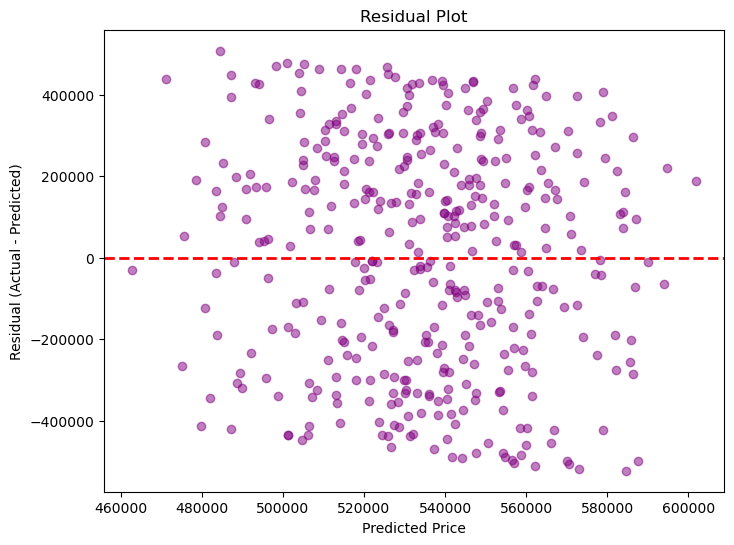

In [17]:
# Calcualte residuals: the data difference between actual and predicted prices
# A residual of 0 means a perfect prediction for that house
residuals = Y_test - Y_pred

# Create the residual plot
plt.figure(figsize=(8, 6))
plt.scatter(Y_pred, residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Price')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot')
plt.show()

Residual Plot: Residuals are randomly scattered around zero with no finnel shape or curved pattern, indicating the model isn't violating linear regression's core assumptions (no heteroscedasticity, no missed non-linear relationship). However, residuals are large in magnitude (up to ±`$400k- $500k`) relative to the narrow range of predicted prices (~460k-600k), reflecting the same lack of predictive power seen in the R² score and correlation analysis. The issue is an absence of signal in the features, not a incorrect model choice.

In [18]:
# Pair each feature with its learned coefficient
coefficients = pd.Series(model.coef_, index=X_train.columns)
coefficients_sorted = coefficients.sort_values(ascending=False)

print(coefficients_sorted)

Condition_Fair       24083.307846
Floors               23727.983633
Location_Suburban    11511.989815
Condition_Poor        4073.268930
Garage_Yes            2373.530579
Location_Rural        1317.542020
YearBuilt              117.613885
Bedrooms                76.784827
Area                    -0.575754
Bathrooms            -9662.248234
Location_Urban      -12718.918912
Condition_Good      -12941.044835
dtype: float64


Coefficient Analysis: The learned coefficients don't  align with eal-world housing intuition. Area expected to be the strongest driver of price has a coefficient of -0.58, implying larger houses are predicted to be slightly cheaper, the opposite of typical housing market behavior. Its magnitude is also negligible (less than `$1` per sq ft). Similarly, Condition_Good shows a negative coefficient (-`$12,941`) while Condition_Poor shows a positive one (+`$11,512`), again this is backwards from expectations. This pattern confirms the model has fit to noise rather tha genuine price-driving relationships, consistent with the near-zero correlations and R² score found earlier.

In [19]:
from sklearn.linear_model import Ridge, Lasso

# Train Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, Y_train)
Y_pred_ridge = ridge.predict(X_test)

# Train Lasso Regression
lasso = Lasso(alpha=1.0)
lasso.fit(X_train, Y_train)
Y_pred_lasso = lasso.predict(X_test)

# Evaluate both
print('Ridge - RMSE:', np.sqrt(mean_squared_error(Y_test, Y_pred_ridge)))
print('Ridge - R²:', r2_score(Y_test, Y_pred_ridge))
print()
print('Lasso - RMSE:', np.sqrt(mean_squared_error(Y_test, Y_pred_lasso)))
print('Lasso - R²:', r2_score(Y_test, Y_pred_lasso))
print()
print('Linear Regression - RMSE:', rmse)
print('Linear Regression - R²:', r2)

Ridge - RMSE: 279859.3725930338
Ridge - R²: -0.0067152670317334184

Lasso - RMSE: 279859.5470196583
Lasso - R²: -0.006716521933428643

Linear Regression - RMSE: 279859.72583784326
Linear Regression - R²: -0.006717808430749761


Bonus: Ridge/Lasso Comparison: Ridge and Lasso regularization produced virtually identical performance to plain Linear Regression (RMSE ≈ $279, 859 and R² ≈ -0.0067 for all three models). This confirms that the poor model performance isn't due to overfitting or noisy/redundant features that regularization could correct, rather it reflects a genuine absence of predictive relationship between the available features and Price in this dataset. Regularization cannot recover signal that isn't present in the data.